In [2]:
import numpy as np
import pandas as pd
import scanpy as sc
import squidpy as sq

/home/bingxing2/ailab/scxlab0179/.conda/envs/bio/lib/python3.11/site-packages/dask/dataframe/__init__.py:31: FutureWarning: The legacy Dask DataFrame implementation is deprecated and will be removed in a future version. Set the configuration option `dataframe.query-planning` to `True` or None to enable the new Dask Dataframe implementation and silence this warning.
  warnings.warn(
/home/bingxing2/ailab/scxlab0179/.conda/envs/bio/lib/python3.11/site-packages/anndata/utils.py:434: FutureWarning: Importing read_text from `anndata` is deprecated. Import anndata.io.read_text instead.
  warnings.warn(msg, FutureWarning)


In [ ]:
# import sys
# sys.path.insert(1, '/home/bingxing2/ailab/group/ai4bio/sunjianle/Descart/code')

from utils import *
import episcanpy as epi
import time
import umap

In [ ]:
# 设置 Matplotlib 的参数
import matplotlib.pyplot as plt
import matplotlib as mpl
mpl.rcParams['pdf.fonttype'] = 42 
mpl.rcParams['ps.fonttype'] = 42

In [ ]:
adata_raw = sc.read_h5ad("/home/bingxing2/ailab/group/ai4bio/sunjianle/mouse_pmc/Yao-2021-ATAC.h5ad")
imputed = sc.read("/home/bingxing2/ailab/group/ai4bio/sunjianle/mouse_pmc/adata_aligned_trained_imputed.h5ad")
imputed = imputed[imputed.obs.modality=="atac",:].copy()
adata_raw = adata_raw[imputed.obs.index,:].copy()
adata_raw.obsm['spatial'] = imputed.obsm['X_spatial_imputed'].copy()
adata_raw.write_h5ad("/home/bingxing2/ailab/group/ai4bio/sunjianle/mouse_pmc/atac_imputed.h5ad")

rna svg

In [ ]:
adata_raw = sc.read_h5ad("/home/bingxing2/ailab/group/ai4bio/sunjianle/mouse_pmc/Yao-2021-RNA.h5ad")
imputed = sc.read("/home/bingxing2/ailab/group/ai4bio/sunjianle/mouse_pmc/adata_aligned_trained_imputed.h5ad")
imputed = imputed[imputed.obs.modality=="rna",:].copy()
adata_raw = adata_raw[imputed.obs.index,:].copy()
adata_raw
adata_raw.obsm['spatial'] = imputed.obsm['X_spatial_imputed'].copy()

In [92]:
adata_raw

AnnData object with n_obs × n_vars = 14107 × 27123
    obs: 'x', 'cluster_label', 'subclass_label', 'class_label', 'cluster_color', 'size', 'aggr_num', 'umi.counts', 'gene.counts', 'library_id', 'tube_barcode', 'Seq_batch', 'Region', 'Lib_type', 'Gender', 'Donor', 'Amp_Name', 'Amp_Date', 'Amp_PCR_cyles', 'Lib_Name', 'Lib_Date', 'Replicate_Lib', 'Lib_PCR_cycles', 'Lib_PassFail', 'Cell_Capture', 'Lib_Cells', 'Mean_Reads_perCell', 'Median_Genes_perCell', 'Median_UMI_perCell', 'Saturation', 'Live_percent', 'Total_Cells', 'Live_Cells', 'method', 'exp_component_name', 'mapped_reads', 'unmapped_reads', 'nonconf_mapped_reads', 'total.reads', 'doublet.score', 'domain', 'protocol', 'dataset', 'cell_type'
    var: 'gene_ids', 'feature_types', 'genome', 'chrom', 'chromStart', 'chromEnd', 'name', 'score', 'strand', 'thickStart', 'thickEnd', 'itemRgb', 'blockCount', 'blockSizes', 'blockStarts', 'gene_type', 'gene_name', 'mgi_id', 'havana_gene', 'tag', 'n_counts', 'highly_variable', 'highly_variable_

In [93]:
adata_raw.write_h5ad("/home/bingxing2/ailab/group/ai4bio/sunjianle/mouse_pmc/rna_imputed.h5ad")

In [ ]:
adata_raw = sc.read_h5ad("/home/bingxing2/ailab/group/ai4bio/sunjianle/mouse_pmc/ATAC_gas.h5ad")
imputed = sc.read("/home/bingxing2/ailab/group/ai4bio/sunjianle/mouse_pmc/adata_aligned_trained_imputed.h5ad")
imputed = imputed[imputed.obs.modality=="atac",:].copy()
adata_raw = adata_raw[imputed.obs.index,:].copy()
adata_raw.obsm['spatial'] = imputed.obsm['X_spatial_imputed'].copy()
adata_raw

AnnData object with n_obs × n_vars = 7102 × 20563
    obs: 'sample', 'barcode', 'TN', 'UM', 'PP', 'UQ', 'CM', 'tsne_0', 'tsne_1', 'cluster', 'region', 'MajorCluster', 'SubCluster', 'domain', 'protocol', 'dataset', 'cell_type', 'batch'
    var: 'gene_status', 'annotation', 'havana_gene', 'gene_type', 'gene_id', 'tag', 'level'
    obsm: 'spatial'
    layers: 'counts'

In [95]:
adata_raw.write_h5ad("/home/bingxing2/ailab/group/ai4bio/sunjianle/mouse_pmc/atac_gas_imputed.h5ad")

visualization

In [9]:
adata = sc.read("/home/bingxing2/ailab/group/ai4bio/sunjianle/mouse_pmc/st_processed.h5ad")
svg1 = pd.read_csv("/home/bingxing2/ailab/group/ai4bio/sunjianle/mouse_pmc/svg_st.csv")

In [10]:
adata

AnnData object with n_obs × n_vars = 6319 × 254
    obs: 'fovID', 'fov_x', 'fov_y', 'volume', 'center_x', 'center_y', 'slice_id', 'sample_id', 'BICCN_cluster_label', 'BICCN_subclass_label', 'BICCN_class_label', 'BICCN_ontology_term_id', 'assay_ontology_term_id', 'disease_ontology_term_id', 'tissue_ontology_term_id', 'cell_type_ontology_term_id', 'self_reported_ethnicity_ontology_term_id', 'development_stage_ontology_term_id', 'sex_ontology_term_id', 'is_primary_data', 'organism_ontology_term_id', 'donor_id', 'suspension_type', 'tissue_type', 'cell_type', 'assay', 'disease', 'organism', 'sex', 'tissue', 'self_reported_ethnicity', 'development_stage', 'observation_joinid', 'batch'
    var: 'feature_is_filtered', 'feature_name', 'feature_reference', 'feature_biotype', 'feature_length', 'feature_type'
    uns: 'BICCN_cluster_label_colors', 'BICCN_subclass_label_colors', 'cell_type_colors', 'cell_type_ontology_term_id_colors', 'citation', 'donor_id_colors', 'log1p', 'schema_reference', 'sch

In [11]:
svg_st = svg1.gene_name[:10]

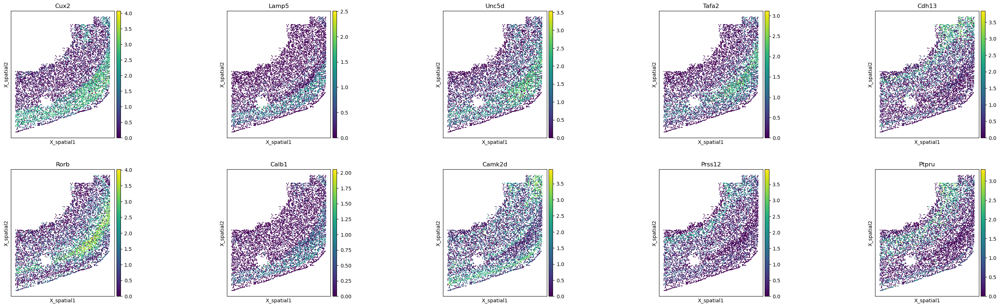

In [ ]:
sq.pl.spatial_scatter(adata, 
                      library_id=None,
                       spatial_key='X_spatial',  
                       color=svg_st,
                       size=1.5,        
                       title=svg_st,
                      ncols=5,
                     shape=None)

In [13]:
adata = sc.read("/home/bingxing2/ailab/group/ai4bio/sunjianle/mouse_pmc/rna_imputed.h5ad")
svg = pd.read_csv("/home/bingxing2/ailab/group/ai4bio/sunjianle/mouse_pmc/svg_rna.csv")
svg_rna = svg.loc[(svg['adjustedPval']==0)&(svg['highly_variable_rank']<600),'gene_name'].to_list()

In [14]:
adata.layers["counts"] = adata.X.copy()
sc.pp.normalize_total(adata)
sc.pp.log1p(adata)

In [15]:
len(svg_rna)

15

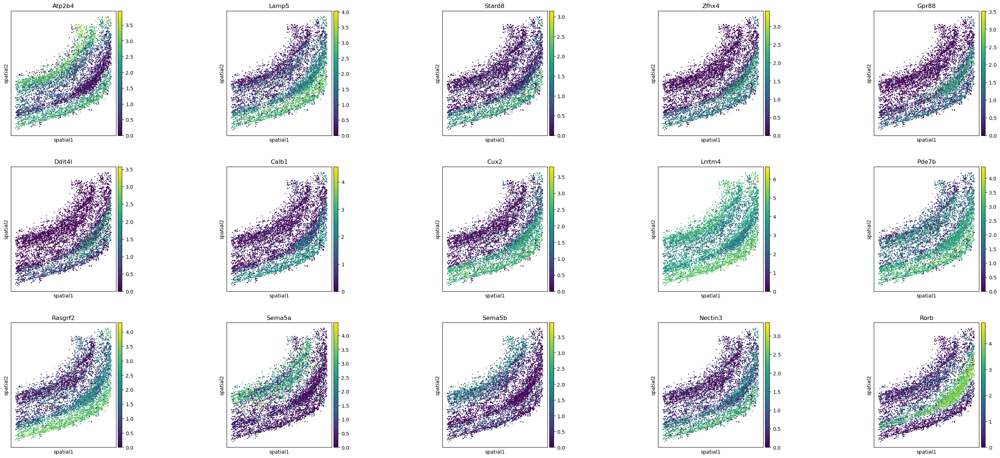

In [ ]:
sq.pl.spatial_scatter(adata, 
                      library_id=None,
                      spatial_key='spatial',  
                      color=svg_rna,
                      size=1.5,        
                      title=svg_rna,
                      ncols=5,
                      shape=None)

In [17]:
svg_st1 = list(set(svg1.loc[svg1['adjustedPval']<1e-95,'gene_name'])&set(svg.gene_name))
len(svg_st1)

15

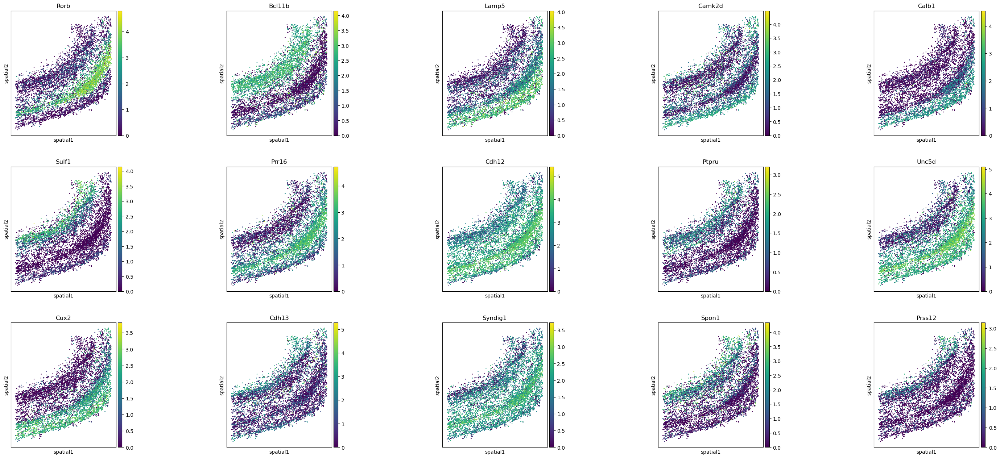

In [ ]:
sq.pl.spatial_scatter(adata, 
                      library_id=None,
                       spatial_key='spatial',  
                       color=svg_st1,
                       size=1.5,     
                       title=svg_st1,
                      ncols=5,
                     shape=None)

Visualization

In [1]:
# 设置 Matplotlib 的参数
import matplotlib.pyplot as plt
import matplotlib as mpl
mpl.rcParams['pdf.fonttype'] = 42  # 确保文本为矢量
mpl.rcParams['ps.fonttype'] = 42

In [4]:
adata = sc.read("/home/bingxing2/ailab/group/ai4bio/sunjianle/mouse_pmc/rna_imputed.h5ad")
adata

AnnData object with n_obs × n_vars = 14107 × 27123
    obs: 'x', 'cluster_label', 'subclass_label', 'class_label', 'cluster_color', 'size', 'aggr_num', 'umi.counts', 'gene.counts', 'library_id', 'tube_barcode', 'Seq_batch', 'Region', 'Lib_type', 'Gender', 'Donor', 'Amp_Name', 'Amp_Date', 'Amp_PCR_cyles', 'Lib_Name', 'Lib_Date', 'Replicate_Lib', 'Lib_PCR_cycles', 'Lib_PassFail', 'Cell_Capture', 'Lib_Cells', 'Mean_Reads_perCell', 'Median_Genes_perCell', 'Median_UMI_perCell', 'Saturation', 'Live_percent', 'Total_Cells', 'Live_Cells', 'method', 'exp_component_name', 'mapped_reads', 'unmapped_reads', 'nonconf_mapped_reads', 'total.reads', 'doublet.score', 'domain', 'protocol', 'dataset', 'cell_type'
    var: 'gene_ids', 'feature_types', 'genome', 'chrom', 'chromStart', 'chromEnd', 'name', 'score', 'strand', 'thickStart', 'thickEnd', 'itemRgb', 'blockCount', 'blockSizes', 'blockStarts', 'gene_type', 'gene_name', 'mgi_id', 'havana_gene', 'tag', 'n_counts', 'highly_variable', 'highly_variable_

/home/bingxing2/ailab/scxlab0179/.conda/envs/bio/lib/python3.11/site-packages/squidpy/pl/_spatial_utils.py:976: UserWarning: No data for colormapping provided via 'c'. Parameters 'cmap', 'norm' will be ignored
  _cax = scatter(


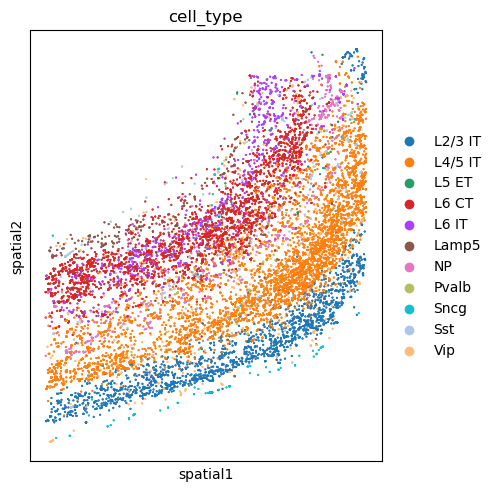

In [5]:
sq.pl.spatial_scatter(adata, library_id=None,spatial_key = 'spatial', 
                      color=["cell_type"],shape=None,size=1,save="/home/bingxing2/ailab/group/ai4bio/sunjianle/mouse_pmc/rna_imputed_spatial.pdf")

/home/bingxing2/ailab/scxlab0179/.conda/envs/bio/lib/python3.11/site-packages/squidpy/pl/_spatial_utils.py:976: UserWarning: No data for colormapping provided via 'c'. Parameters 'cmap', 'norm' will be ignored
  _cax = scatter(
/home/bingxing2/ailab/scxlab0179/.conda/envs/bio/lib/python3.11/site-packages/squidpy/pl/_spatial_utils.py:976: UserWarning: No data for colormapping provided via 'c'. Parameters 'cmap', 'norm' will be ignored
  _cax = scatter(


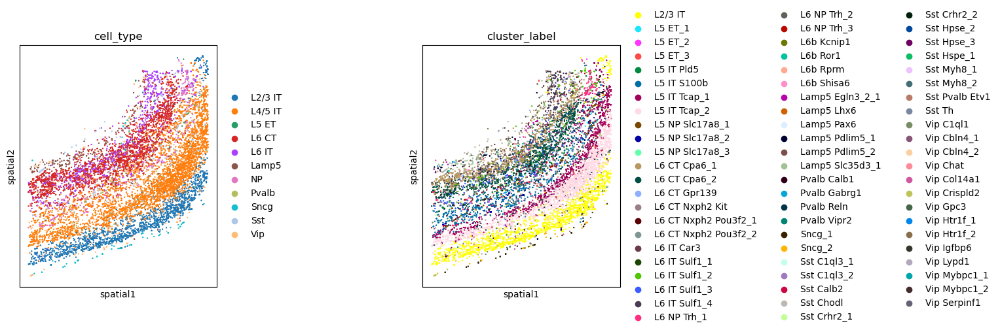

In [6]:
sq.pl.spatial_scatter(adata, library_id=None,spatial_key = 'spatial', 
                      color=["cell_type",'cluster_label'],shape=None,size=1)

In [7]:
adata = sc.read("/home/bingxing2/ailab/group/ai4bio/sunjianle/mouse_pmc/atac_gas_imputed.h5ad")
adata

AnnData object with n_obs × n_vars = 7102 × 20563
    obs: 'sample', 'barcode', 'TN', 'UM', 'PP', 'UQ', 'CM', 'tsne_0', 'tsne_1', 'cluster', 'region', 'MajorCluster', 'SubCluster', 'domain', 'protocol', 'dataset', 'cell_type', 'batch'
    var: 'gene_status', 'annotation', 'havana_gene', 'gene_type', 'gene_id', 'tag', 'level'
    obsm: 'spatial'
    layers: 'counts'

/home/bingxing2/ailab/scxlab0179/.conda/envs/bio/lib/python3.11/site-packages/squidpy/pl/_spatial_utils.py:976: UserWarning: No data for colormapping provided via 'c'. Parameters 'cmap', 'norm' will be ignored
  _cax = scatter(


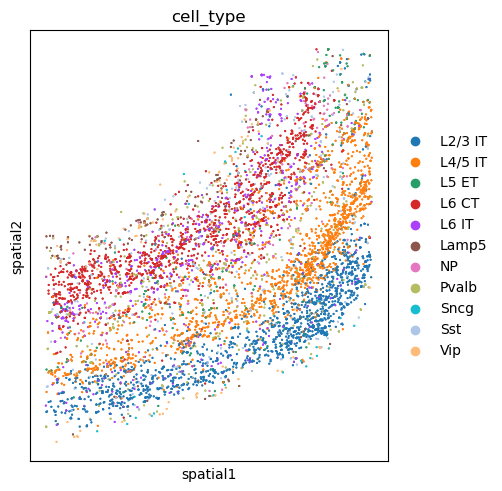

In [8]:
sq.pl.spatial_scatter(adata, library_id=None,spatial_key = 'spatial', 
                      color=["cell_type"],shape=None,size=1,save="/home/bingxing2/ailab/group/ai4bio/sunjianle/mouse_pmc/atac_imputed_spatial.pdf")

/home/bingxing2/ailab/scxlab0179/.conda/envs/bio/lib/python3.11/site-packages/squidpy/pl/_spatial_utils.py:976: UserWarning: No data for colormapping provided via 'c'. Parameters 'cmap', 'norm' will be ignored
  _cax = scatter(
/home/bingxing2/ailab/scxlab0179/.conda/envs/bio/lib/python3.11/site-packages/squidpy/pl/_spatial_utils.py:976: UserWarning: No data for colormapping provided via 'c'. Parameters 'cmap', 'norm' will be ignored
  _cax = scatter(


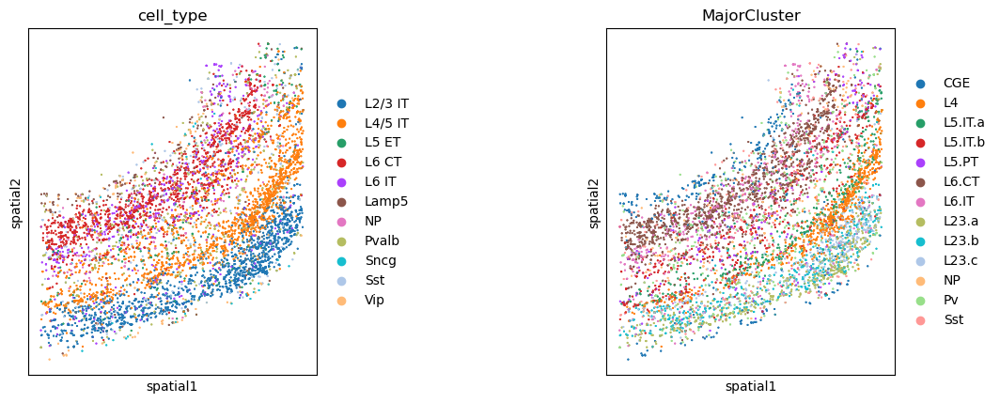

In [9]:
sq.pl.spatial_scatter(adata, library_id=None,spatial_key = 'spatial', 
                      color=["cell_type","MajorCluster"],shape=None,size=1)

In [10]:
adata = sc.read("/home/bingxing2/ailab/group/ai4bio/sunjianle/mouse_pmc/st_processed.h5ad")
adata

AnnData object with n_obs × n_vars = 6319 × 254
    obs: 'fovID', 'fov_x', 'fov_y', 'volume', 'center_x', 'center_y', 'slice_id', 'sample_id', 'BICCN_cluster_label', 'BICCN_subclass_label', 'BICCN_class_label', 'BICCN_ontology_term_id', 'assay_ontology_term_id', 'disease_ontology_term_id', 'tissue_ontology_term_id', 'cell_type_ontology_term_id', 'self_reported_ethnicity_ontology_term_id', 'development_stage_ontology_term_id', 'sex_ontology_term_id', 'is_primary_data', 'organism_ontology_term_id', 'donor_id', 'suspension_type', 'tissue_type', 'cell_type', 'assay', 'disease', 'organism', 'sex', 'tissue', 'self_reported_ethnicity', 'development_stage', 'observation_joinid', 'batch'
    var: 'feature_is_filtered', 'feature_name', 'feature_reference', 'feature_biotype', 'feature_length', 'feature_type'
    uns: 'BICCN_cluster_label_colors', 'BICCN_subclass_label_colors', 'cell_type_colors', 'cell_type_ontology_term_id_colors', 'citation', 'donor_id_colors', 'log1p', 'schema_reference', 'sch

/home/bingxing2/ailab/scxlab0179/.conda/envs/bio/lib/python3.11/site-packages/squidpy/pl/_spatial_utils.py:976: UserWarning: No data for colormapping provided via 'c'. Parameters 'cmap', 'norm' will be ignored
  _cax = scatter(
/home/bingxing2/ailab/scxlab0179/.conda/envs/bio/lib/python3.11/site-packages/squidpy/pl/_spatial_utils.py:976: UserWarning: No data for colormapping provided via 'c'. Parameters 'cmap', 'norm' will be ignored
  _cax = scatter(


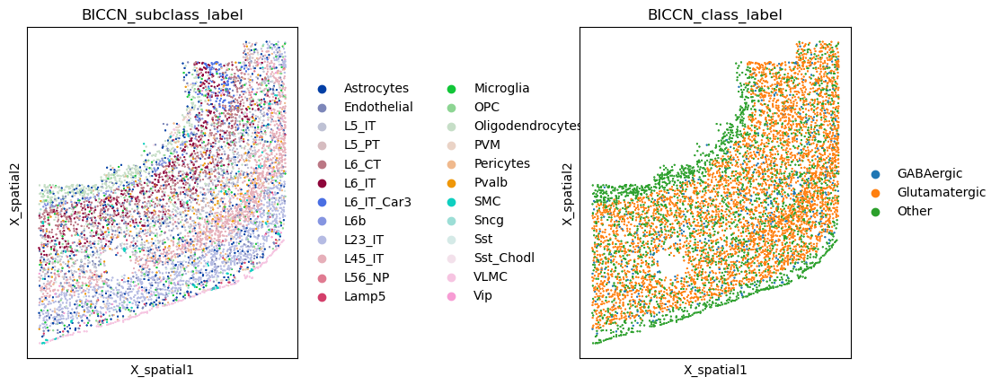

In [11]:
sq.pl.spatial_scatter(adata, library_id=None,spatial_key = 'X_spatial', 
                      color=["BICCN_subclass_label","BICCN_class_label"],shape=None,size=1)

/home/bingxing2/ailab/scxlab0179/.conda/envs/bio/lib/python3.11/site-packages/squidpy/pl/_spatial_utils.py:976: UserWarning: No data for colormapping provided via 'c'. Parameters 'cmap', 'norm' will be ignored
  _cax = scatter(


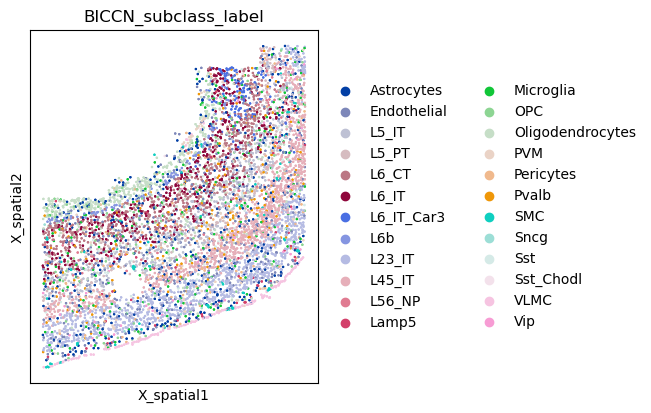

In [12]:
sq.pl.spatial_scatter(adata, library_id=None,spatial_key = 'X_spatial', 
                      color=["BICCN_subclass_label"],shape=None,size=2,save="/home/bingxing2/ailab/group/ai4bio/sunjianle/mouse_pmc/st_spatial.pdf")

In [13]:
import pandas as pd
import numpy as np

In [14]:
svg1 = pd.read_csv("/home/bingxing2/ailab/group/ai4bio/sunjianle/mouse_pmc/svg_st.csv")
svg2 = pd.read_csv("/home/bingxing2/ailab/group/ai4bio/sunjianle/mouse_pmc/svg_rna.csv")
svg3 = pd.read_csv("/home/bingxing2/ailab/group/ai4bio/sunjianle/mouse_pmc/svg_atac_gas.csv")

In [15]:
svg_list1 = svg1.loc[svg1['adjustedPval']<1e-20,'gene_name']
svg_list2 = svg2.loc[svg2['adjustedPval']<1e-20,'gene_name']
svg_list3 = svg3.loc[svg3['adjustedPval']<1e-20,'gene_name']

In [16]:
print(len(svg_list1))
print(len(svg_list2))
print(len(list(set(svg_list1)&set(svg_list2))))
print(len(list(set(svg_list1)&set(svg2['gene_name']))))
print(svg1.shape[0])
print(svg2.shape[0])
print(len(svg_list3))

103
4095
83
101
254
26050
142


In [17]:
print(len(svg_list1))
print(len(svg_list2))
print(len(list(set(svg_list1)&set(svg_list2))))
print(len(list(set(svg_list1)&set(svg2['gene_name']))))
print(svg1.shape[0])
print(svg2.shape[0])
print(len(svg_list3))

103
4095
83
101
254
26050
142


In [18]:
st = sc.read("/home/bingxing2/ailab/group/ai4bio/sunjianle/mouse_pmc/st_processed.h5ad")
rna = sc.read("/home/bingxing2/ailab/group/ai4bio/sunjianle/mouse_pmc/rna_imputed.h5ad")
atac = sc.read("/home/bingxing2/ailab/group/ai4bio/sunjianle/mouse_pmc/atac_gas_imputed.h5ad")

In [19]:
sc.pp.normalize_total(rna, target_sum=1e4)
sc.pp.log1p(rna)
sc.pp.normalize_total(atac, target_sum=1e4)
sc.pp.log1p(atac)

In [20]:
sc.pp.highly_variable_genes(rna, n_top_genes = 400)
rna_hvg = rna.var.loc[rna.var.highly_variable,:].index

In [21]:
distinct_genes = list(set(svg2.loc[(svg2['adjustedPval']==0)&((svg2['highly_variable_rank']<250))&(svg2["gene_type"]=="protein_coding"),'gene_name'].to_list())-set(svg1.gene_name))
distinct_genes # 

['Rprm', 'Hs3st4', 'Cpa6', 'Thsd7b', 'Zfpm2']

In [22]:
common_genes = svg1.loc[svg1['gene_name'].isin(svg_list2),:].sort_values("adjustedPval").head(5).loc[:,'gene_name'].values
common_genes

array(['Cux2', 'Lamp5', 'Unc5d', 'Cdh13', 'Rorb'], dtype=object)

In [23]:
import os
os.chdir("/home/bingxing2/ailab/group/ai4bio/sunjianle/mouse_pmc")

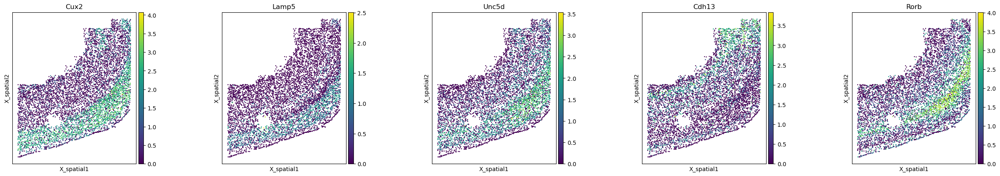

In [24]:
sq.pl.spatial_scatter(st, 
                      library_id=None,
                       spatial_key='X_spatial',  # 根据需要选择图像键
                       color=common_genes,
                       size=1.5,         # 点的大小
                       title=common_genes,
                      ncols=5,
                      wspace=0, 
                     shape=None,
                     save="st_common_svg.pdf")

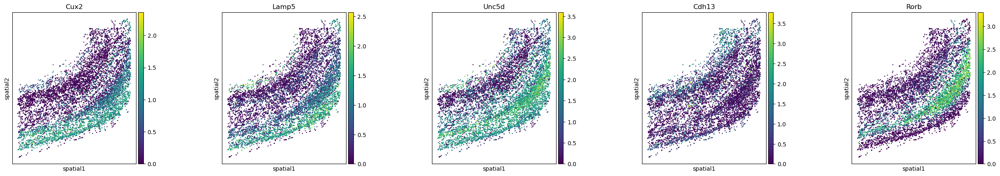

In [25]:
sq.pl.spatial_scatter(rna, 
                      library_id=None,
                      spatial_key='spatial',  # 根据需要选择图像键
                      color=common_genes,
                      size=1.5,         # 点的大小
                      title=common_genes,
                      ncols=5,
                      wspace=0,
                      shape=None,
                     save="rna_common_svg.pdf")

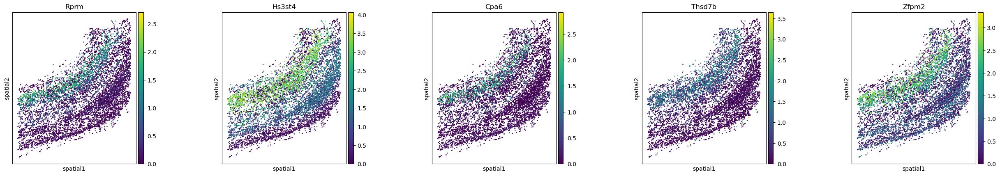

In [26]:
sq.pl.spatial_scatter(rna, 
                      library_id=None,
                      spatial_key='spatial',  # 根据需要选择图像键
                      color=distinct_genes,
                      size=1.5,         # 点的大小
                      title=distinct_genes,
                      ncols=5,
                      wspace=0,
                      shape=None,
                     save="rna_distinct_svg.pdf")

In [27]:
sc.pp.highly_variable_genes(atac, n_top_genes = 500)

In [28]:
atac_hvg = atac.var.loc[atac.var.highly_variable,:].index

In [29]:
top_atac = svg3.loc[(svg3['gene_name'].isin(atac_hvg)) & (svg3['gene_name'].isin(svg_list3)) &(svg3["gene_type"]=="protein_coding"),:].sort_values('adjustedPval').head(5).loc[:,'gene_name'].values

In [30]:
top_atac

array(['Unc5d', 'Gpc5', 'Sntg2', 'Btbd3', 'Nrp2'], dtype=object)

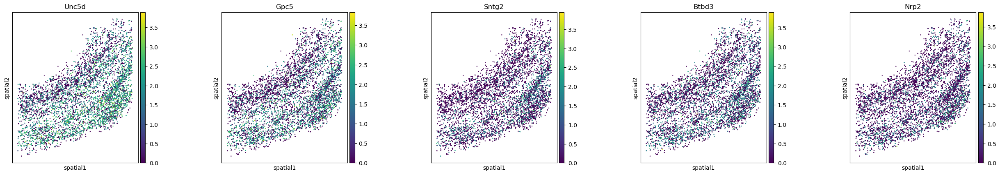

In [31]:
sq.pl.spatial_scatter(atac, 
                      library_id=None,
                      spatial_key='spatial',  # 根据需要选择图像键
                      color=top_atac,
                      size=1.5,         # 点的大小
                      title=top_atac,
                      ncols=5,
                      wspace=0,
                      shape=None,
                     save="atac_top_svg.pdf")

In [32]:
top20_st = svg1.sort_values("adjustedPval").head(20).loc[:,'gene_name'].values

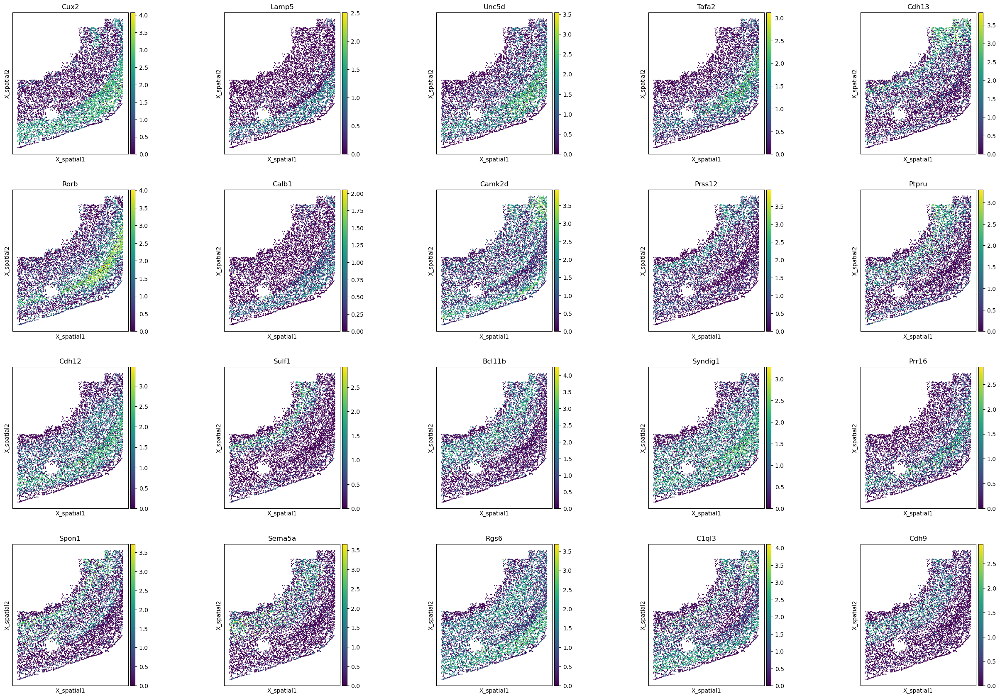

In [33]:
sq.pl.spatial_scatter(st, 
                      library_id=None,
                       spatial_key='X_spatial',  # 根据需要选择图像键
                       color=top20_st,
                       size=1.5,         # 点的大小
                       title=top20_st,
                      ncols=5,
                      wspace=0, 
                     shape=None,
                     save="st_top20.pdf")

In [34]:
top20_rna = svg2.loc[(svg2['adjustedPval']==0)&((svg2['highly_variable_rank']<390))&(svg2["gene_type"]=="protein_coding"),'gene_name'].to_list()

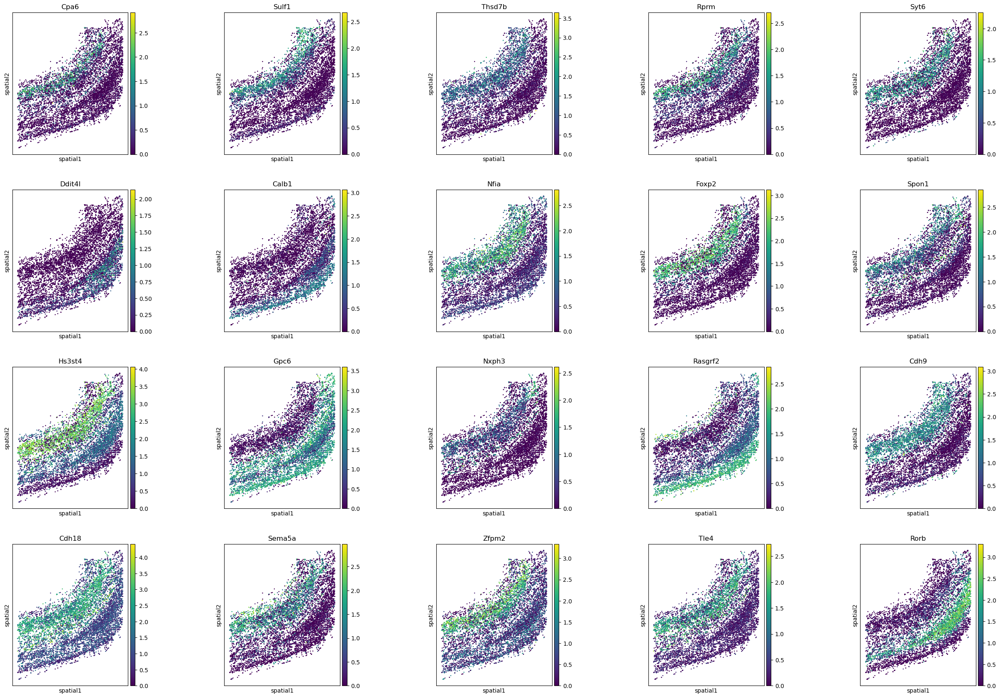

In [35]:
sq.pl.spatial_scatter(rna, 
                      library_id=None,
                      spatial_key='spatial',  # 根据需要选择图像键
                      color=top20_rna,
                      size=1.5,         # 点的大小
                      title=top20_rna,
                      ncols=5,
                      wspace=0,
                      shape=None,
                     save="rna_top20.pdf")

In [36]:
top20_atac = svg3.loc[(svg3['gene_name'].isin(svg_list3)) &(svg3["gene_type"]=="protein_coding"),:].sort_values('adjustedPval').head(20).loc[:,'gene_name'].values

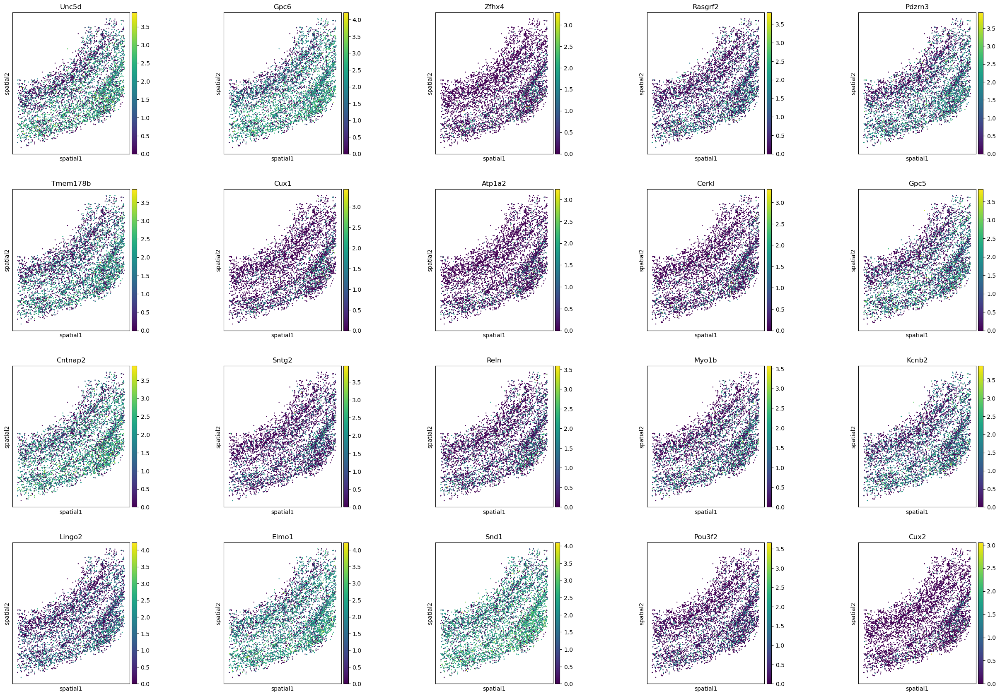

In [37]:
sq.pl.spatial_scatter(atac, 
                      library_id=None,
                      spatial_key='spatial',  # 根据需要选择图像键
                      color=top20_atac,
                      size=1.5,         # 点的大小
                      title=top20_atac,
                      ncols=5,
                      wspace=0,
                      shape=None,
                     save="atac_top20.pdf")